# <span style="color:blue"> Lecture 17: Neural Networks and Tensor Flow </span>

<font size = "5">

In this class we will talk about how to set up <br>
a neural network classifier using Tensor Flow

For an introduction

https://www.youtube.com/watch?v=i8NETqtGHms

# Neural Net notes:

$X_i$ : covariates, regressors, features

$\hat{Y_i} \in {0,1}$ : output set of possibilities

$X_i \rightarrow {0,1}$

Evaluation task is comparing $Y_i$ vs $\hat{Y_i}$
- Accuracy = % of times when $Y_i = \hat{Y_i}$
- False Positive Rate = $\frac{\text{\% of times } Y_i = 0 \text{ and } \hat{Y}_i = 1}
{\text{\% of times } Y_i = 0}$  = $P(\hat{Y}_i = 1 \mid Y_i = 0)$


## LOGIT:

$$
\begin{aligned}
P(Y_i=1 \mid X_i=x)
&= \frac{e^{\beta_0+\beta_1X_{1i}+\beta_2X_{2i}+\dots+\beta_kX_{ki}}}
{1+e^{\beta_0+\beta_1X_{ii}+\beta_2X_{2i}+\dots+\beta_kX_{ki}}} \\
&= \frac{e^{f(X_i,\beta)}}{1+e^{f(X_i,\beta)}} \\
&= \frac{1}{1+e^{-f(X_i,\beta)}}
\end{aligned}
$$

$\sigma(z) = \frac{1}{1+e^{-z}} \leftarrow$ SIGMOID activation function

$\beta \leftarrow$ weights, loadings, coefficients


#### Single Layer LOGIT neural network

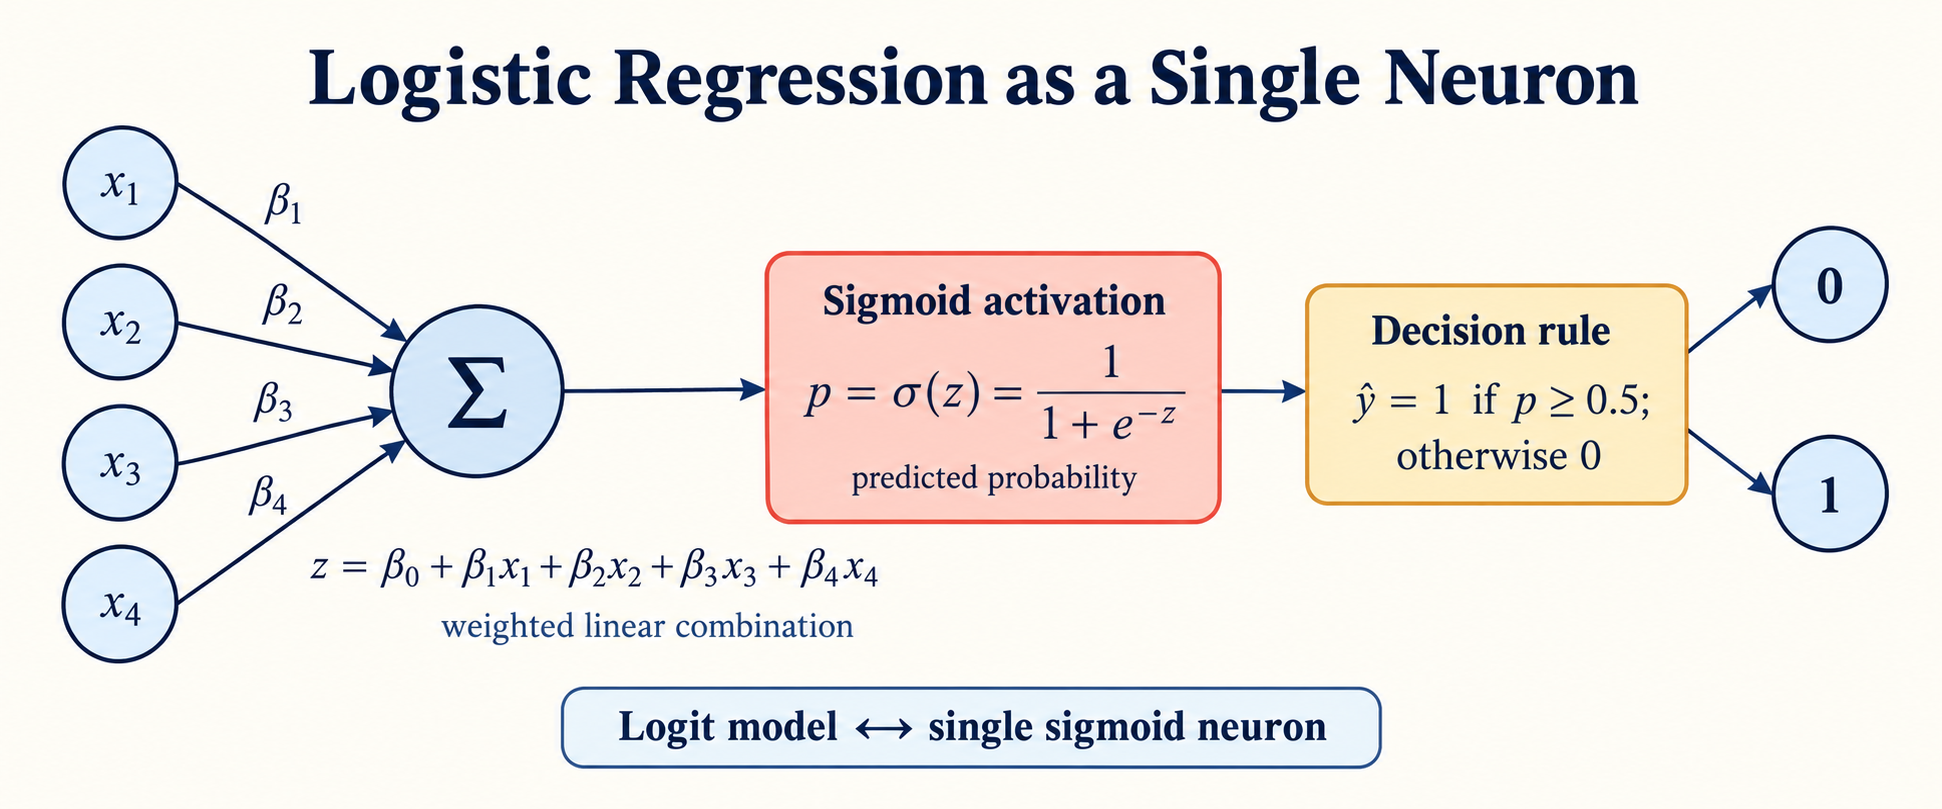

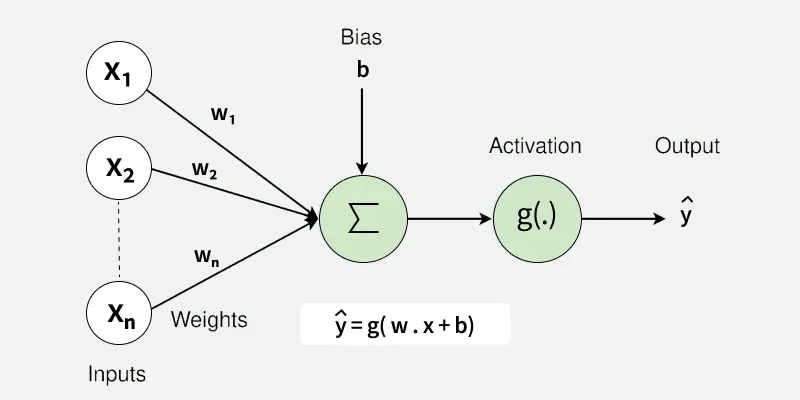

#### 2-Layer neural network

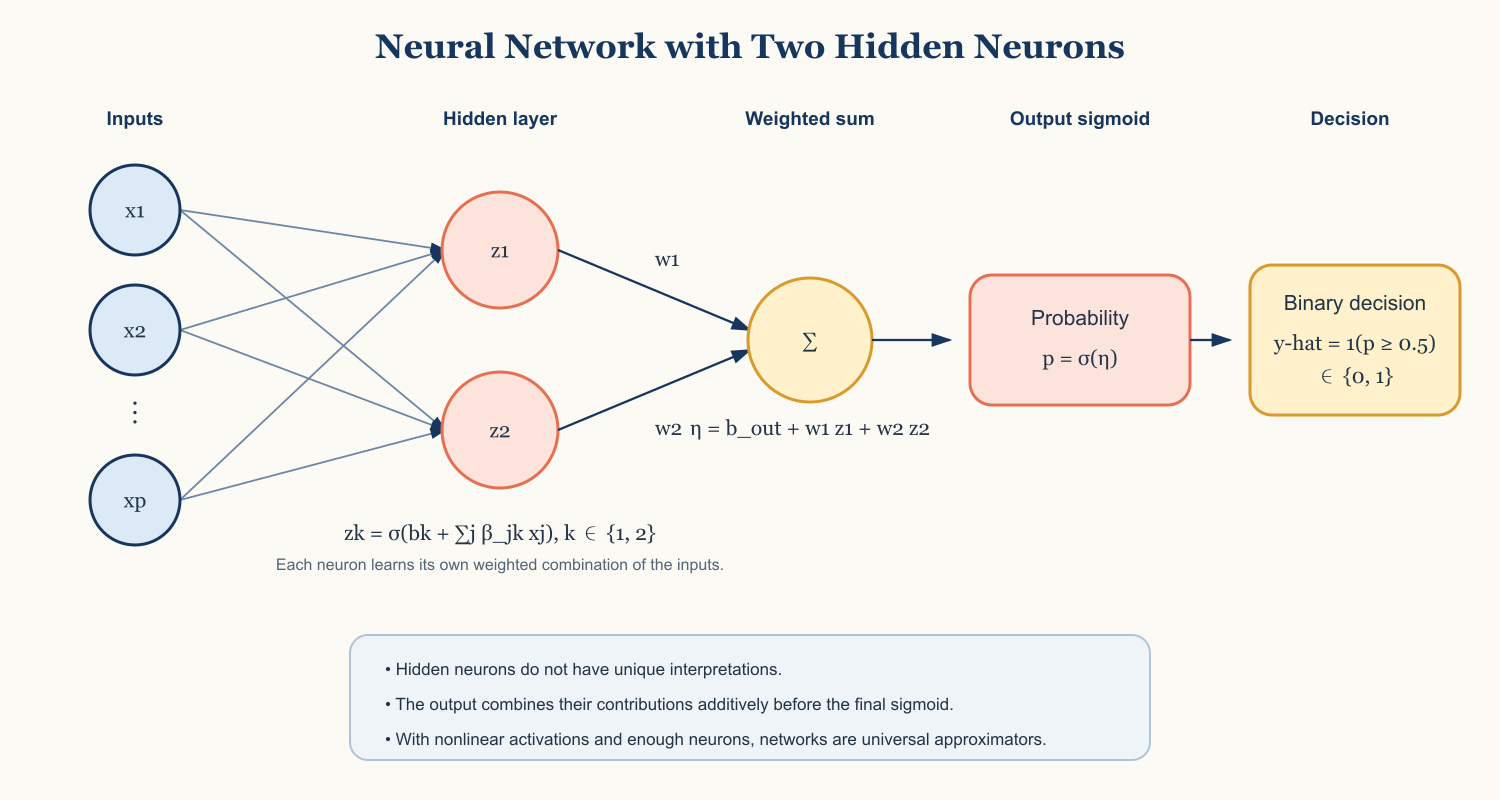

* network layers are NOT unique - goal is to see the big picture, not what's happening at each individual layer
* Added value of more neurons $\rightarrow$ neural nets have a property known as being UNIVERSAL APPROXIMATORS
    - Universal Approximator: can approximate any continuous function as closely as desired—provided it has enough hidden units and suitable nonlinear activation functions.
        - guarantee: an appropriate network exists, but learning that relationship is a separate challenge

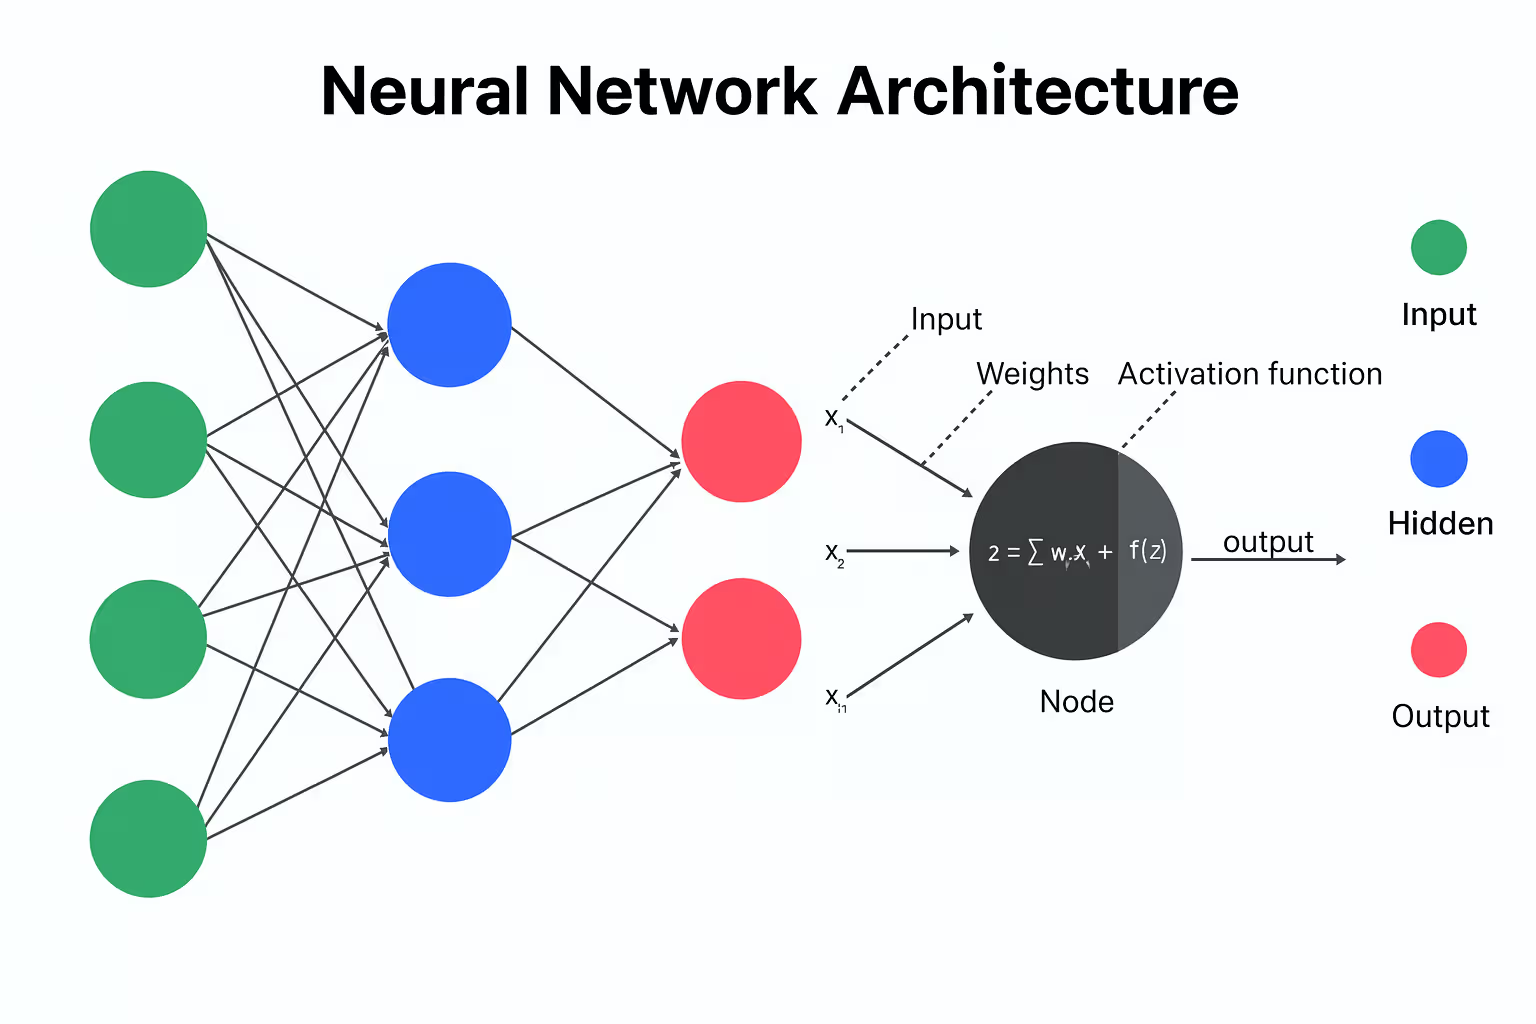

## Neural Net Models in Python
### 1. Model Configuration
    - inputs
    - architecturs $\leftarrow$ 
        - # layers
        - # neurons per layer
            - output layer = # possible outcomes/categories/labels/etc. 
        - activation function : Sigmoid, ReLu, etc. 
            - sigmoid:  defines predictions in (0,1)
            - ReLu : 
    - output
    - Loss function
    - optimizer: how weights are updated
    - hyperparameters: Settings selected before training, including
        -  *learning rate* : Controls the size of each weight update
        - *batch size* :subset of training observations used for one update
        - *number of epochs*: one complete pass through the training data
        -  *hidden-layer size*
### 2. Estimation
    - estimating layer weights and biases with training data
    - For each batch of observations, the network performs:
        1. Forward propagation: Inputs move through the network to produce predictions.
        2. Loss calculation: Predictions are compared with the correct targets.
        3. Backpropagation: The network calculates how each weight contributed to the error.
        4. Weight update: The optimizer adjusts weights to reduce the loss.
        5. Repetition: This process continues across multiple epochs.
### 3. Evaluation
Choose metrics appropriate for the task:
- Regression: MAE, MSE, RMSE, or \(R^2\)
- Classification: Accuracy, precision, recall, F1 score, ROC-AUC, or log loss
- Imbalanced classification: Precision, recall, F1, and PR-AUC are often more informative than accuracy

# <span style="color:blue"> I. Setup Working Environment </span>



<font size = "5">

We will be using a new library called "Tensor Flow" that is used <br>
to create neural network architectures

In Windows (Anaconda Prompt) or Mac (Terminal) type:

``` conda install tensorflow ```

In [1]:
# Import the package for the University of California Irvine API
from ucimlrepo import fetch_ucirepo 

# Import SK-Learn library for machine learning functions
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate
from sklearn import preprocessing
from sklearn.metrics import get_scorer_names


# Import standard data analysis packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


Environment note: Before running this notebook, select the Python (Computing 530 — TensorFlow) kernel in VS Code. TensorFlow is installed in this project’s .venv-tensorflow environment and may not load correctly from the Anaconda base kernel.

<font size = "5">

Import tensor flow packages

In [2]:
# Import standard data analysis packages
import tensorflow as tf
from tensorflow import keras
from keras.layers import Dense

# <span style="color:blue"> II. Data </span>

<font size = "5">

Online Shoppers Purchasing Intention Dataset (OSHPID)

- This dataset contains information about user sessions
- It contains features data about user behavior 
while <br> navigating website
- The goal is to predict whether the customer will purchase or not

https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset


In [3]:
# Fetch online data from the UC Irvine Machine Learning Repository API
online_shopping= fetch_ucirepo(id=468) 

# Extract
X = online_shopping.data.features
# Drop columns that contain non-numeric values
X = X.drop(columns = ["Month","VisitorType"])

# Extract label data
y = online_shopping.data.targets["Revenue"]


In [4]:
# Convert to float types (avoids issues down the line)
X = np.asarray(X).astype(np.float32)
y = np.asarray(y).astype(np.float32)

<font size = "5">

Pre-process data prior to running model

In [5]:
# Split into training and test
X_train, X_test, y_train, y_test = train_test_split(X,y , 
                                   random_state=104,  
                                   test_size=0.25,  
                                   shuffle=True) 

In [6]:
# The first step is to produce a "scaler" function
scaler_train = preprocessing.StandardScaler().fit(X_train)
scaler_test  = preprocessing.StandardScaler().fit(X_test)

# Apply scaler function
X_train_scale = scaler_train.transform(X_train)
X_test_scale  = scaler_test.fit(X_test).transform(X_test)

# <span style="color:blue"> III. Training a neural network </span>


<font size = "5">

Define number of features in $X$

In [10]:
k_features = X.shape[1]
print(k_features)

15


<font size = "5">

To define a neural network we start with a configuration setup

- We start with an empty canvas with "Keras"
- Then we successively add how many layers we want <br>
and what type

For more information about Keras layers:

https://www.educative.io/answers/what-are-keras-layers

In [ ]:
# "basic_model" for now only starts with a configuration

basic_model = keras.models.Sequential() 

2025-11-04 11:13:44.358408: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [12]:
# We add how many layers we want, starting with the input layer and 
# ending with the output layer

# This has a dense layer for inputs with "k" features
basic_model.add(Dense(units=16, activation='relu', input_shape=(k_features,)))

# This is the output layer. The sigmoid defines predictions in (0,1)
# We choose 1 unit since there is a scalar output (binary classification)

basic_model.add(Dense(units = 1, activation='sigmoid'))

# Note: If you are using the neural network to predict continuous outcomes,
# you may want a different activation function in the output layer

<font size = "5">

Define an optimizer

In [13]:
# Adam is a type of optimization algorithm

adam = keras.optimizers.Adam(learning_rate=0.001)

In [14]:
# Define the loss function to optimize

basic_model.compile(loss='binary_crossentropy', optimizer=adam, metrics=["accuracy"])

<font size = "5">

Estimate model

- The optimization algorithm proceeds sequentially, through epocs
- Set a random seed to ensure reproducibility

In [15]:
# Set random seed
tf.keras.utils.set_random_seed(0)  

# Train model
basic_model.fit(X_train, y_train, epochs=100)

Epoch 1/100
289/289 [==============================] - 0s 440us/step - loss: 6.6818 - accuracy: 0.7841
Epoch 2/100
289/289 [==============================] - 0s 421us/step - loss: 0.8210 - accuracy: 0.8603
Epoch 3/100
289/289 [==============================] - 0s 410us/step - loss: 0.6388 - accuracy: 0.8642
Epoch 4/100
289/289 [==============================] - 0s 403us/step - loss: 0.6016 - accuracy: 0.8656
Epoch 5/100
289/289 [==============================] - 0s 408us/step - loss: 0.5993 - accuracy: 0.8630
Epoch 6/100
289/289 [==============================] - 0s 422us/step - loss: 0.5989 - accuracy: 0.8648
Epoch 7/100
289/289 [==============================] - 0s 423us/step - loss: 0.5551 - accuracy: 0.8626
Epoch 8/100
289/289 [==============================] - 0s 425us/step - loss: 0.5531 - accuracy: 0.8616
Epoch 9/100
289/289 [==============================] - 0s 553us/step - loss: 0.7121 - accuracy: 0.8565
Epoch 10/100
289/289 [==============================] - 0s 430us/step - l

# <span style="color:blue"> IV. Evaluate a neural network </span>


<font size = "5">

Obtain predicted probabilities and convert them to {0,1}

In [16]:
# Convert to array
predicted_prob = basic_model.predict(X_test)
predicted_prob = tf.squeeze(predicted_prob)

# Convert to {0,1} predictions using a 0.5 threshold
threshold = 0.5
predicted = np.array([1 if x >= threshold else 0 for x in predicted_prob])

97/97 [==============================] - 0s 339us/step


<font size = "5">

Obtain confusion matrix

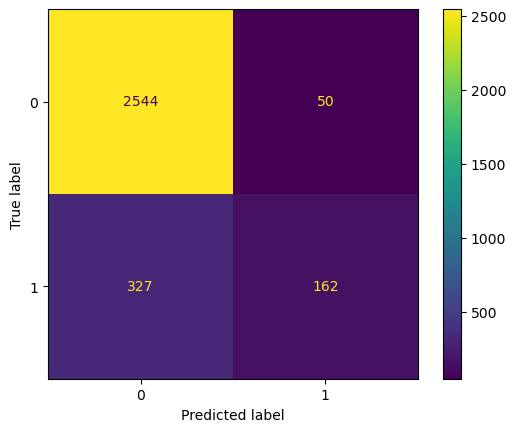

In [17]:
# Obtain confusion matrix
cm = confusion_matrix(y_test, predicted)

displ = ConfusionMatrixDisplay(confusion_matrix=cm)
displ.plot()

<font size = "5">

At the moment we defined a very simple neural network <br>
with just an input layer and an output layer. <br>

Try it yourself!

- Increase the number of units in the input layer
- Does prediction accuracy improve?


In [ ]:
# Write your own code




<font size = "5">


Try it yourself!

- Add one or more hidden layers
- Does prediction accuracy improve?

In [ ]:
# Write your own code






<font size = "5">

Try it yourself!

- Import the Mashable dataset that we used earlier <br>
(you can find this in this in the ```ArticlesTrain.csv``` and <br>
```ArticlesTest.csv``` files in the ```data_raw``` folder)

- Try to set up a neural network with a simple input-output layer 

In [ ]:
# Write your own code






# <span style="color:blue"> V. Additional resources </span>

<font size = "5">

Quick guide:

https://www.tensorflow.org/tutorials/quickstart/beginner

Binary classification:

https://www.freecodecamp.org/news/binary-classification-made-simple-with-tensorflow/

Image classification:

https://www.tensorflow.org/tutorials/images/classification

